In [136]:
using Plots, VeryDiff, VeryDiffPolyExperiments, SpecialFunctions, JLD2, Plots.Measures

In [2]:
include(joinpath(@__DIR__, "..", "..", "..", "PolynomialEquivalenceNN", "src", "piecewise_polynomial", "gelu_approx.jl"))

┌ Info: Defined Φ and gelu!
└ @ Main /home/philipp/VerifyNN/PolynomialEquivalenceNN/src/piecewise_polynomial/gelu_approx.jl:28


save_piecewise_poly (generic function with 1 method)

In [3]:
# the gelu_approx.jl file already contains the definition of gelu.
# gelu = x -> 0.5 * x * (1 + erf(x / sqrt(2)))

In [4]:
gpp = VeryDiff.load_piecewise_poly(joinpath(@__DIR__, "..", "..", "..", "PolynomialEquivalenceNN", "gelu_piecewise_poly_sampled_degree_15.jld2"))
f_gpp = VeryDiff.make_eval_gelu_piecewise_poly(gpp)

#make_eval_gelu_piecewise_poly##0 (generic function with 1 method)

In [5]:
function error_sampling(f_p, f, l, u; n_samples=10000)
    xs = range(l, u, n_samples)
    ϵ  = maximum(abs.(f_p.(xs) .- f.(xs)))
    i  = argmax(abs.(f_p.(xs) .- f.(xs)))
    return ϵ, xs[i]
end

error_sampling (generic function with 1 method)

In [4]:
l, u = -3., 6.
d = 5
p_approx_pw, ϵ = VeryDiff.remez(f_gpp, (p, l, u) -> VeryDiff.piecewise_poly_error(gpp, p, l, u), VeryDiff.poly_norm, l, u, d, verbosity=1, max_iter=20)
    #f = VeryDiff.make_eval_chebyshev(p_approx_pw, l, u)
    #ϵ = error_sampling(f, gelu, l, u) 

step, |error|,  |level|,  tol_diff, ref_diff
1     0.152643  0.033237  0.059703  9.000000
2     0.078644  0.063726  0.007459  0.305036
3     0.069877  0.068899  0.000489  0.056694
4     0.068944  0.068943  0.000001  0.002106
5     0.068943  0.068943  0.000000  0.000001
Tolerance of 1.0e-10 reached (4.3721970488519446e-14)!


([2.229234698357821, 3.203103243171212, 0.8599454514672509, -0.32803820931785965, -0.034594408456383396, 0.13929197562146886], 0.06894275676312216)

# Synthesis of Polynomial Networks

(p_gelu, ϵ) = ([2.1543273512879004, 3.3751362661329396, 0.843647798704803], 0.37311142214516746)
(ϵ_sample, x_opt) = (0.37311142204534586, -3.0)


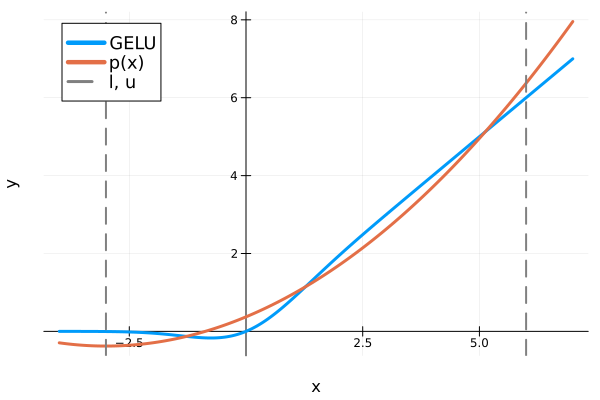

In [35]:
l, u = -3., 6.
d = 2
δ = 1.

p_gelu, ϵ = VeryDiff.approx_gelu_poly(l, u, d)
f_gelu = VeryDiff.make_eval_chebyshev(p_gelu, l, u)
ϵ_sample, x_opt = error_sampling(f_gelu, gelu, l, u)

@show p_gelu, ϵ
@show ϵ_sample, x_opt

xs = range(l - δ, u + δ, 200)
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)
vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

In [36]:
savefig(pl, "../fig/retreat/gelu_quad_approx.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_quad_approx.pdf"

x_maxs = [-3.0, 0.0, 3.061206120612061, 6.0]


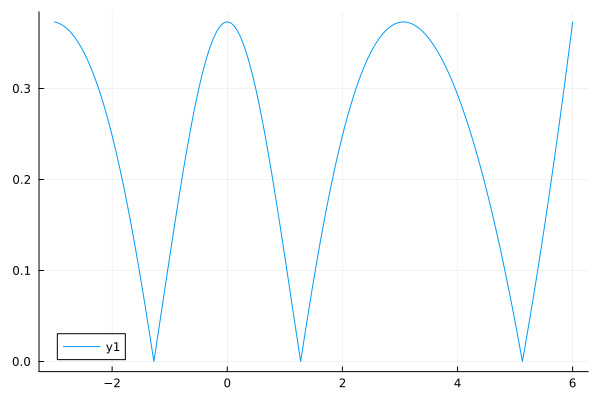

In [37]:
# stupid trick, but it does the job for now 

xis = range(l, u, 10000)
ϵs = abs.(f_gelu.(xis) .- gelu.(xis))
ϵ_max = maximum(ϵs)

x_maxs = xis[ϵs .>= 0.9999999 * ϵ_max]
@show x_maxs

plot(xis, ϵs)

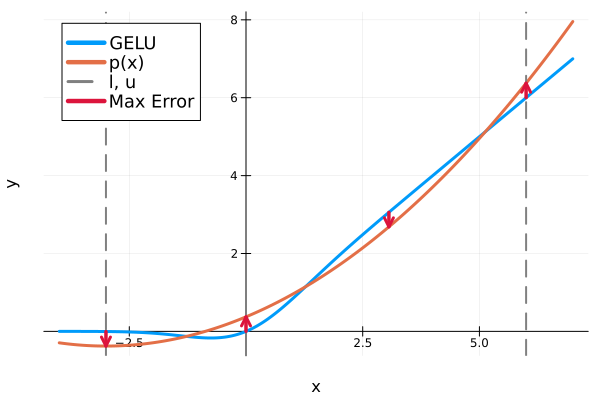

In [38]:
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)
vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

for (i, x_max) in enumerate(x_maxs)
    if i == 1
        plot!([x_max, x_max], [gelu(x_max), f_gelu(x_max)], arrow = true, color = :crimson, lw = 3, label = "Max Error")
    else
        plot!([x_max, x_max], [gelu(x_max), f_gelu(x_max)], arrow = true, color = :crimson, lw = 3, label = "")
    end
end

pl

In [39]:
savefig(pl, "../fig/retreat/gelu_quad_approx_error.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_quad_approx_error.pdf"

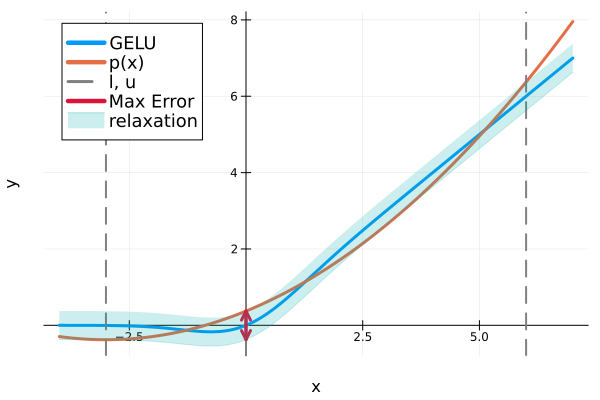

In [40]:
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)

vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

plot!([0, 0], [gelu(0), gelu(0) + ϵ_max], arrow = true, color = :crimson, lw = 3, label = "Max Error")
plot!([0, 0], [gelu(0), gelu(0) - ϵ_max], arrow = true, color = :crimson, lw = 3, label = "")

plot!(xs, gelu.(xs) .- ϵ_max, fillrange=gelu.(xs) .+ ϵ_max, alpha=0.2, label="relaxation")

In [41]:
savefig(pl, "../fig/retreat/gelu_quad_approx_band.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_quad_approx_band.pdf"

# Monotonically Linear Almost Everywhere Activation Functions

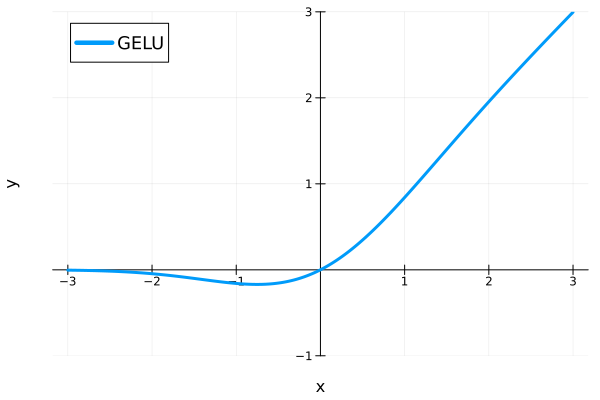

In [94]:
l, u = -3., 3.
xs = range(l, u, 200)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)

In [95]:
savefig(pl, "../fig/retreat/gelu_mlae.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_mlae.pdf"

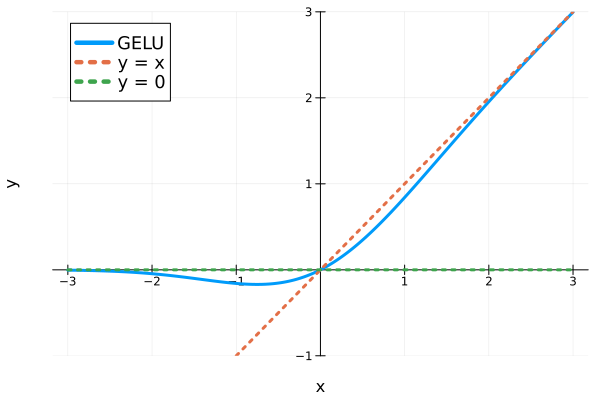

In [96]:
l, u = -3., 3.
xs = range(l, u, 200)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)

In [97]:
savefig(pl, "../fig/retreat/gelu_linear_asmyptotes.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_linear_asmyptotes.pdf"

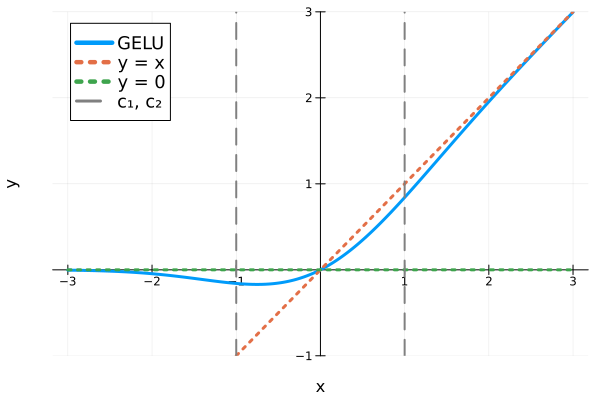

In [98]:
l, u = -3., 3.
xs = range(l, u, 200)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)

In [99]:
savefig(pl, "../fig/retreat/gelu_c0_c1.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_c0_c1.pdf"

gelu(d₀) = -0.15865525393145707


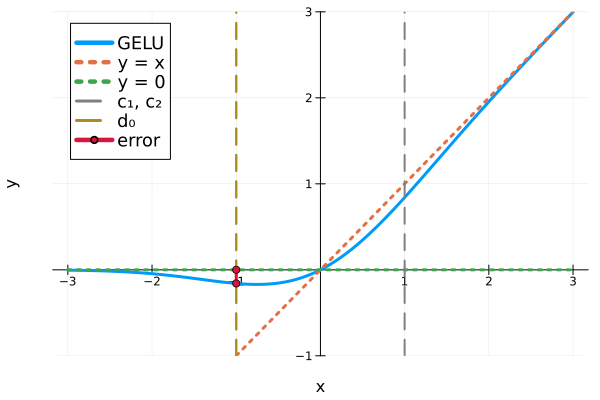

In [100]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = -1.
@show gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀], label="d₀", lw=2, ls=:dash)

plot!([d₀, d₀], [gelu(d₀), 0], color = :crimson, lw = 3, label = "error", marker=:circle)

In [101]:
savefig(pl, "../fig/retreat/gelu_binary_search1.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_binary_search1.pdf"

gelu(d₀) = -0.04550026389635842


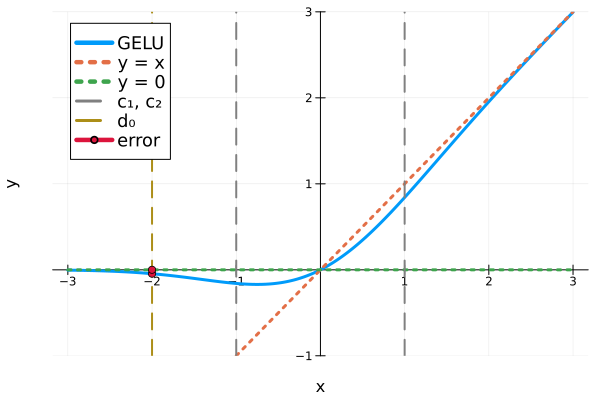

In [102]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = -2.
@show gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀], label="d₀", lw=2, ls=:dash)

plot!([d₀, d₀], [gelu(d₀), 0], color = :crimson, lw = 3, label = "error", marker=:circle)

In [103]:
savefig(pl, "../fig/retreat/gelu_binary_search2.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_binary_search2.pdf"

gelu(d₀) = -0.10021080190328713


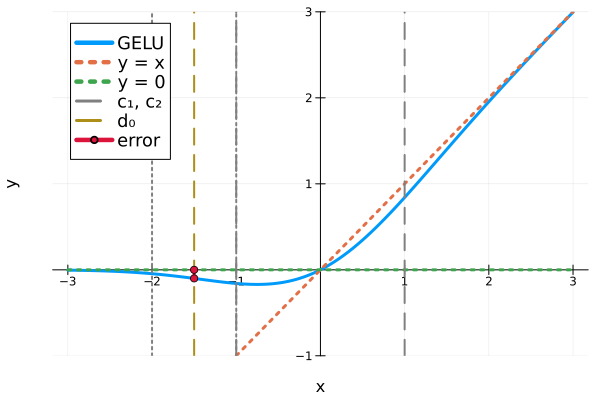

In [104]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = 0.5 * (-2 + -1)
@show gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀], label="d₀", lw=2, ls=:dash)

vline!([-2., -1.], label="", lw=2, ls=:dot, color=:gray)

plot!([d₀, d₀], [gelu(d₀), 0], color = :crimson, lw = 3, label = "error", marker=:circle)

In [105]:
savefig(pl, "../fig/retreat/gelu_binary_search3.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_binary_search3.pdf"

(d₀, gelu(d₀)) = (-1.75, -0.07010352451167995)


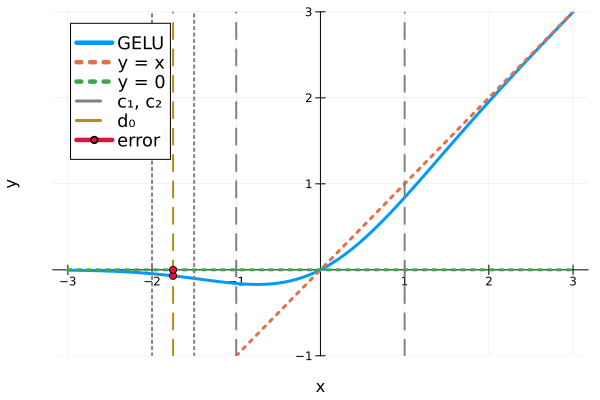

In [106]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = 0.5 * (-2. + 0.5 * (-2 + -1))
@show d₀, gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀], label="d₀", lw=2, ls=:dash)

vline!([-2., -1.5], label="", lw=2, ls=:dot, color=:gray)

plot!([d₀, d₀], [gelu(d₀), 0], color = :crimson, lw = 3, label = "error", marker=:circle)

In [107]:
savefig(pl, "../fig/retreat/gelu_binary_search4.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_binary_search4.pdf"

(d₀, gelu(d₀)) = (-1.9488610414615744, -0.049999999999999906)


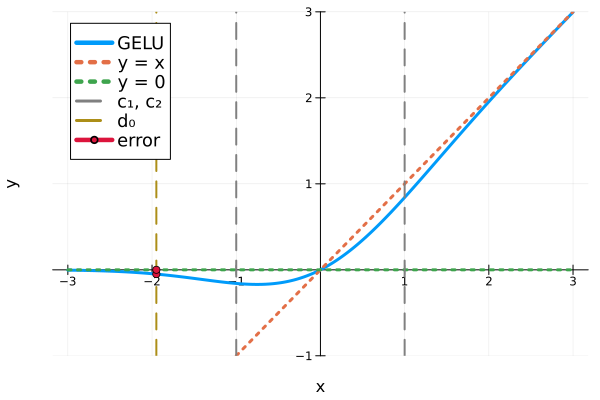

In [108]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = -1.9488610414615744
@show d₀, gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀], label="d₀", lw=2, ls=:dash)

plot!([d₀, d₀], [gelu(d₀), 0], color = :crimson, lw = 3, label = "error", marker=:circle)

In [109]:
savefig(pl, "../fig/retreat/gelu_binary_search5.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_binary_search5.pdf"

(d₀, gelu(d₀)) = (-1.9488610414615744, -0.049999999999999906)


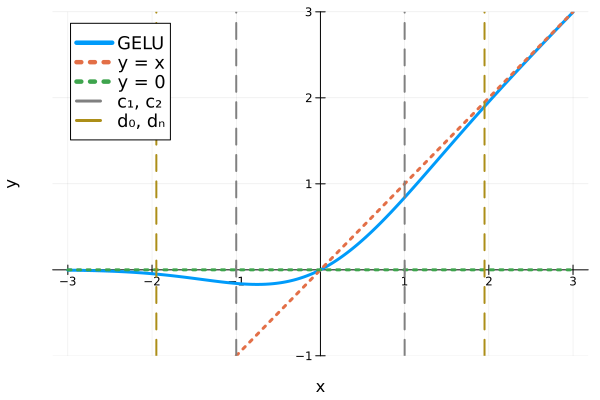

In [112]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = -1.9488610414615744
@show d₀, gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([-1., 1.], label="c₁, c₂", lw=2, ls=:dash, color=:gray)
vline!([d₀, -d₀], label="d₀, dₙ", lw=2, ls=:dash)

In [113]:
savefig(pl, "../fig/retreat/gelu_final_d0_dn.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_final_d0_dn.pdf"

(d₀, gelu(d₀)) = (-1.9488610414615744, -0.049999999999999906)


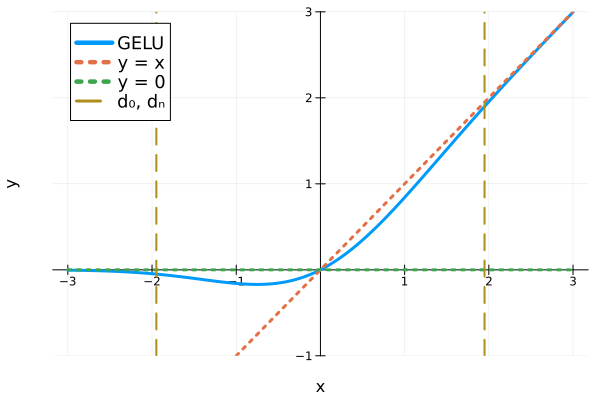

In [115]:
l, u = -3., 3.
xs = range(l, u, 200)
d₀ = -1.9488610414615744
@show d₀, gelu(d₀)

pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", ylims=(-1, u), legendfontsize=12)
plot!(xs, xs, label="y = x", lw=3, ls=:dot)
plot!(xs, zero(xs), label="y = 0", lw=3, ls=:dot)
vline!([d₀, -d₀], label="d₀, dₙ", lw=2, ls=:dash, color=5)

In [116]:
savefig(pl, "../fig/retreat/gelu_final_d0_dn_no_c.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_final_d0_dn_no_c.pdf"

In [117]:
function plot_pw_approx(l, u, a, b, ps, bds, errs; ϵ_desired=0.05, plot_ϵ_desired=false, plot_gelu=true, plot_err=true, n_samples=1000, err_alpha=0.5, plot_only_linear=false)
    xs = range(l, u, n_samples)
    pl = plot(framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)

    ϵ = maximum(errs)

    if plot_gelu
        plot!(xs, gelu.(xs), label="GELU", lw=3, color=1)
    end

    xa = xs[xs .<= a]
    xb = xs[xs .>= b]
    plot!(xa, zero(xa), label="linear 1", lw=3, color=2)
    plot!(xb, xb, label="linear 2", lw=3, color=3)

    if plot_err
        plot!(xa, zero(xa) .- ϵ, fillrange=ϵ, fillalpha=err_alpha, label="", color=2)
        plot!(xb, xb .- ϵ, fillrange=xb .+ ϵ, fillalpha=err_alpha, label="", color=3)
    elseif plot_ϵ_desired
        plot!(xa, zero(xa) .- ϵ_desired, fillrange=ϵ_desired, fillalpha=err_alpha, label="", color=2)
        plot!(xb, xb .- ϵ_desired, fillrange=xb .+ ϵ_desired, fillalpha=err_alpha, label="", color=3)
    end

    if plot_only_linear
        return pl
    end

    for (i, p) in enumerate(ps)
        bl = bds[i] 
        bu = bds[i + 1]
        x_bnds = xs[(xs .>= bl) .& (xs .<= bu)]
        plot!(x_bnds, p.(x_bnds), label="p_$i", lw=3, color=3+i)

        if plot_err
            plot!(x_bnds, p.(x_bnds) .- ϵ, fillrange=p.(x_bnds) .+ ϵ, fillalpha=err_alpha, label="", color=3+i)
        elseif plot_ϵ_desired
            plot!(x_bnds, p.(x_bnds) .- ϵ_desired, fillrange=p.(x_bnds) .+ ϵ_desired, fillalpha=err_alpha, label="", color=3+i)
        end
    end 

    return pl 
end

plot_pw_approx (generic function with 1 method)

[a, b] = [-1.9488610414615744, 1.9488610414615744]
trying with 1 polynomials ...
	 - generating polynomials ...
	subdomain 1 : [-1.9488610414615744, 1.9488610414615744]
	 - concrete error: 0.11287493003228813
	 - error = 0.11287493003228813


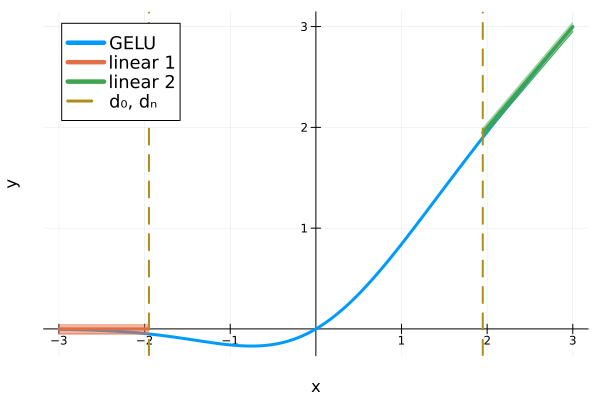

In [119]:
ϵ_max = 0.05
d = 2
max_polys = 1
a, b, ps, bds, errs = approx_gelu_piecewise_poly(ϵ_max, d, max_polys=max_polys, n_samples=1000, bound_method=:sampled)

l, u = -3., 3.
pl = plot_pw_approx(l, u, a, b, ps, bds, errs, plot_err=false, plot_ϵ_desired=true, ϵ_desired=ϵ_max, plot_only_linear=true)

vline!([d₀, -d₀], label="d₀, dₙ", lw=2, ls=:dash, color=5)

In [120]:
savefig(pl, "../fig/retreat/gelu_linear_approx.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_linear_approx.pdf"

[a, b] = [-1.9488610414615744, 1.9488610414615744]
trying with 1 polynomials ...
	 - generating polynomials ...
	subdomain 1 : [-1.9488610414615744, 1.9488610414615744]
	 - concrete error: 0.11287493003228813
	 - error = 0.11287493003228813


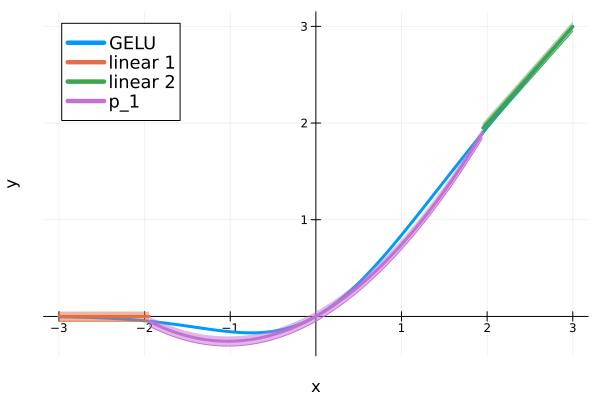

In [121]:
ϵ_max = 0.05
d = 2
max_polys = 1
a, b, ps, bds, errs = approx_gelu_piecewise_poly(ϵ_max, d, max_polys=max_polys, n_samples=1000, bound_method=:sampled)

l, u = -3., 3.
pl = plot_pw_approx(l, u, a, b, ps, bds, errs, plot_err=false, plot_ϵ_desired=true, ϵ_desired=ϵ_max)

In [122]:
savefig(pl, "../fig/retreat/gelu_single_poly_approx.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_single_poly_approx.pdf"

[a, b] = [-1.9488610414615744, 1.9488610414615744]
trying with 1 polynomials ...
	 - generating polynomials ...
	error too large (0.11287493003228813) - skipping to more polys
trying with 2 polynomials ...
	 - generating polynomials ...
	subdomain 1 : [-1.9488610414615744, 0.0]
	 - error = 0.0495608588318376
	subdomain 2 : [0.0, 1.9488610414615744]
	 - error = 0.04995191984117442


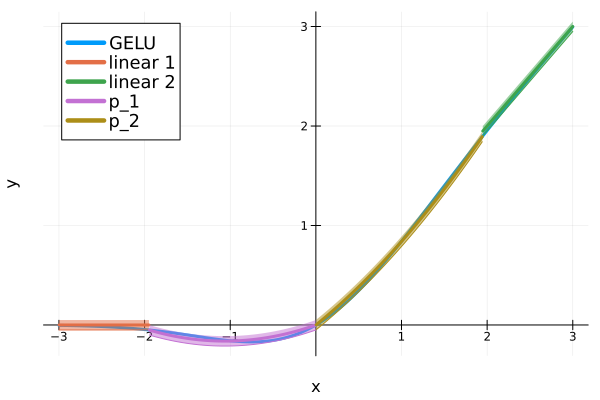

In [123]:
ϵ_max = 0.05
d = 2
max_polys = 3
a, b, ps, bds, errs = approx_gelu_piecewise_poly(ϵ_max, d, max_polys=max_polys, n_samples=1000)

l, u = -3., 3.
pl = plot_pw_approx(l, u, a, b, ps, bds, errs)

In [124]:
savefig(pl, "../fig/retreat/gelu_sufficient_approx_0_05.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_sufficient_approx_0_05.pdf"

[a, b] = [-2.6748097256672847, 2.6748097256672847]
trying with 1 polynomials ...
	 - generating polynomials ...
	error too large (0.2383164597613918) - skipping to more polys
trying with 2 polynomials ...
	 - generating polynomials ...
	error too large (0.08224116096777831) - skipping to more polys
trying with 3 polynomials ...
	 - generating polynomials ...
	error too large (0.011326755775519642) - skipping to more polys
trying with 4 polynomials ...
	 - generating polynomials ...
	error too large (0.01366377062847604) - skipping to more polys
trying with 5 polynomials ...
	 - generating polynomials ...
	subdomain 1 : [-2.6748097256672847, -1.6048858354003708]
	 - error = 0.009635030984426387
	subdomain 2 : [-1.6048858354003708, -0.534961945133457]
	 - error = 0.009912122201919019
	subdomain 3 : [-0.534961945133457, 0.534961945133457]
	 - error = 0.009979276159128747
	subdomain 4 : [0.534961945133457, 1.6048858354003708]
	 - error = 0.009997184068637754
	subdomain 5 : [1.6048858354003

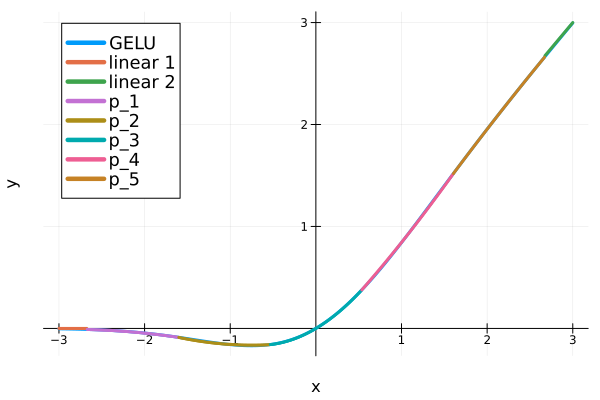

In [125]:
ϵ_max = 0.01
d = 2
max_polys = 6
a, b, ps, bds, errs = approx_gelu_piecewise_poly(ϵ_max, d, max_polys=max_polys, n_samples=1000)

l, u = -3., 3.
pl = plot_pw_approx(l, u, a, b, ps, bds, errs)

In [126]:
savefig(pl, "../fig/retreat/gelu_sufficient_approx_0_01.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/gelu_sufficient_approx_0_01.pdf"

# Further Contributions

## Difference Transformer

(αl, αu, βl, βu) = (0.5000000000000001, 0.5000000000000001, -0.6289041451851548, 0.6289041451851548)


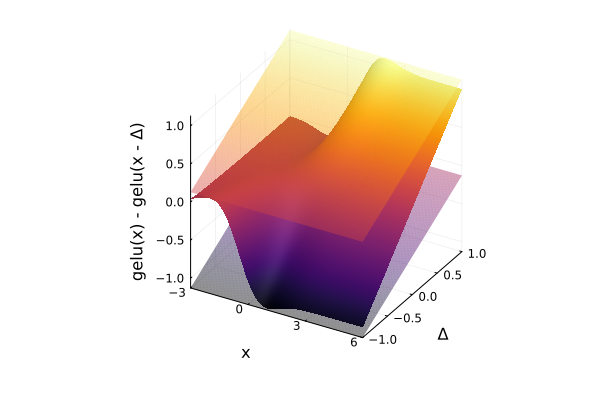

In [198]:
l, u = -3., 6.
lΔ, uΔ = -1., 1.
∂l, ∂u = VeryDiff.Transformers.dgelu_bounds(l, u)

αl = (∂l*uΔ - ∂u*lΔ) / (uΔ - lΔ)
αu = (∂u*uΔ - ∂l*lΔ) / (uΔ - lΔ)
βl = ((∂u - ∂l)*lΔ*uΔ) / (uΔ - lΔ)
βu = -βl

@show αl, αu, βl, βu

xs = range(l, u, 200)
Δs = range(lΔ, uΔ, 200)
f_diff = (x, Δ) -> gelu(x) - gelu(x - Δ)
f_relax_lower = (x, Δ) -> αl*Δ + βl
f_relax_upper = (x, Δ) -> αu*Δ + βu
pl = surface(xs, Δs, f_relax_lower, xlabel="x", ylabel="Δ", zlabel="gelu(x) - gelu(x - Δ)", colorbar=false, alpha=0.5)
surface!(xs, Δs, f_diff)
surface!(xs, Δs, f_relax_upper, alpha=0.5)

In [199]:
savefig(pl, "../fig/retreat/diff_transformer_raven.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/diff_transformer_raven.pdf"

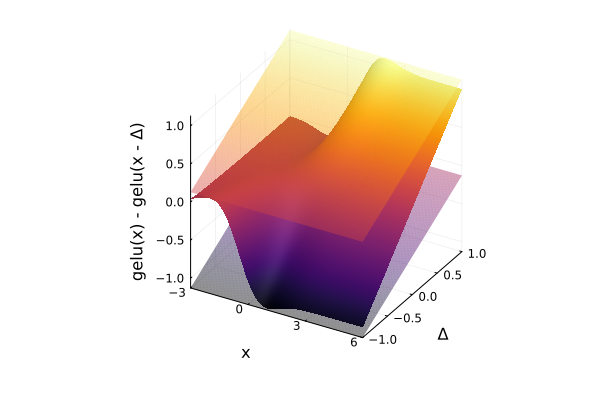

In [200]:
α = 0.5 * (αl + αu)
λl = α - αl
λu = α - αu
bu = ifelse(αu - α >= 0, (αu - α)*uΔ + βu, (αu - α)*lΔ + βu)
bl = ifelse(αl - α >= 0, (αl - α)*lΔ + βl, (αl - α)*uΔ + βl)

xs = range(l, u, 200)
Δs = range(lΔ, uΔ, 200)
f_diff = (x, Δ) -> gelu(x) - gelu(x - Δ)
f_relax_lower = (x, Δ) -> α*Δ + bl
f_relax_upper = (x, Δ) -> α*Δ + bu
pl = surface(xs, Δs, f_relax_lower, xlabel="x", ylabel="Δ", zlabel="gelu(x) - gelu(x - Δ)", colorbar=false, alpha=0.5)
surface!(xs, Δs, f_diff)
surface!(xs, Δs, f_relax_upper, alpha=0.5)

In [201]:
savefig(pl, "../fig/retreat/diff_transformer_zono.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/diff_transformer_zono.pdf"

ϵ = 0.19061101967011052


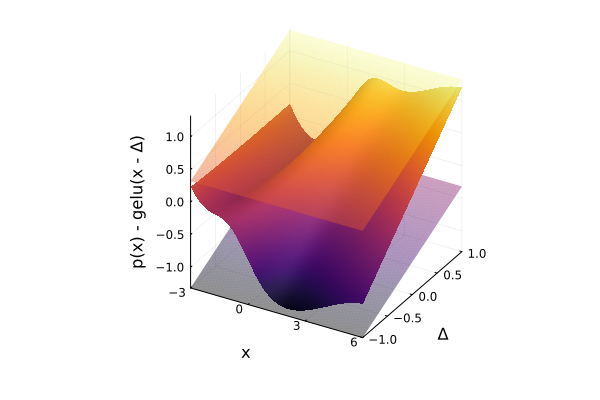

In [202]:
α = 0.5 * (αl + αu)
λl = α - αl
λu = α - αu
bu = ifelse(αu - α >= 0, (αu - α)*uΔ + βu, (αu - α)*lΔ + βu)
bl = ifelse(αl - α >= 0, (αl - α)*lΔ + βl, (αl - α)*uΔ + βl)

p_gelu, ϵ = VeryDiff.approx_gelu_poly(l, u, d)
f_gelu = VeryDiff.make_eval_chebyshev(p_gelu, l, u)

@show ϵ

xs = range(l, u, 200)
Δs = range(lΔ, uΔ, 200)
f_diff = (x, Δ) -> f_gelu(x) - gelu(x - Δ)
f_relax_lower = (x, Δ) -> α*Δ + bl - ϵ
f_relax_upper = (x, Δ) -> α*Δ + bu + ϵ
pl = surface(xs, Δs, f_relax_lower, xlabel="x", ylabel="Δ", zlabel="p(x) - gelu(x - Δ)", colorbar=false, alpha=0.5)
surface!(xs, Δs, f_diff)
surface!(xs, Δs, f_relax_upper, alpha=0.5)

In [203]:
savefig(pl, "../fig/retreat/diff_transformer_poly.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/diff_transformer_poly.pdf"

## Heterogeneous Polynomials

(p_gelu, ϵ) = ([2.2461671074734304, 3.275713743941648, 0.9424190620891724, -0.27368889985387457], 0.19061101967011052)
(ϵ_sample, x_opt) = (0.19061101956990179, 6.0)


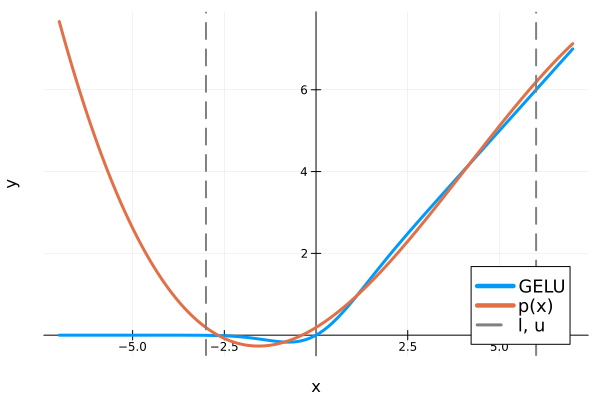

In [178]:
l, u = -3., 6.
l_plot, u_plot = -6., 6.
d = 3
δ = 1.

p_gelu, ϵ = VeryDiff.approx_gelu_poly(l, u, d)
f_gelu = VeryDiff.make_eval_chebyshev(p_gelu, l, u)
ϵ_sample, x_opt = error_sampling(f_gelu, gelu, l, u)

@show p_gelu, ϵ
@show ϵ_sample, x_opt

xs = range(l_plot - δ, u_plot + δ, 200)
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)
vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

In [179]:
savefig(pl, "../fig/retreat/approx_gelu_neg3_6.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/approx_gelu_neg3_6.pdf"

(p_gelu, ϵ) = ([0.7461671074734293, 1.2242862560583543, 0.9424190620891727, 0.27368889985387396], 0.19061101967011262)
(ϵ_sample, x_opt) = (0.19061101956989968, -6.0)


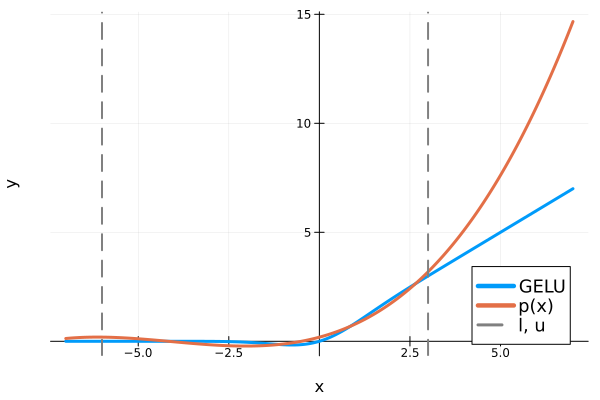

In [180]:
l, u = -6., 3.
l_plot, u_plot = -6., 6.
d = 3
δ = 1.

p_gelu, ϵ = VeryDiff.approx_gelu_poly(l, u, d)
f_gelu = VeryDiff.make_eval_chebyshev(p_gelu, l, u)
ϵ_sample, x_opt = error_sampling(f_gelu, gelu, l, u)

@show p_gelu, ϵ
@show ϵ_sample, x_opt

xs = range(l_plot - δ, u_plot + δ, 200)
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)
vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

In [181]:
savefig(pl, "../fig/retreat/approx_gelu_neg6_3.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/approx_gelu_neg6_3.pdf"

(p_gelu, ϵ) = ([1.873156821629416, 3.0000000000000018, 1.4999999970402378, -5.643633708511212e-16], 0.37315682468917816)
(ϵ_sample, x_opt) = (0.37315682458918076, 6.0)


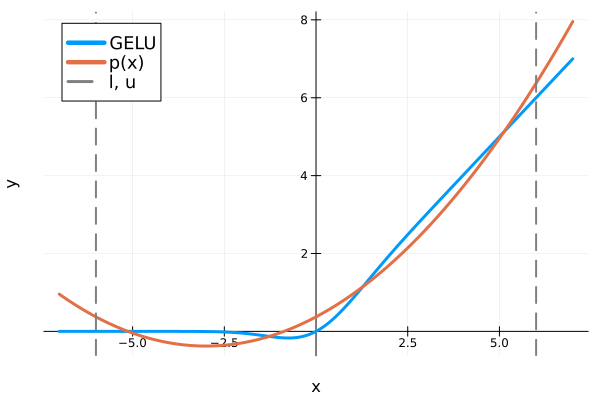

In [183]:
l, u = -6., 6.
l_plot, u_plot = -6., 6.    
d = 3
δ = 1.

p_gelu, ϵ = VeryDiff.approx_gelu_poly(l, u, d)
f_gelu = VeryDiff.make_eval_chebyshev(p_gelu, l, u)
ϵ_sample, x_opt = error_sampling(f_gelu, gelu, l, u)

@show p_gelu, ϵ
@show ϵ_sample, x_opt

xs = range(l_plot - δ, u_plot + δ, 200)
pl = plot(xs, gelu.(xs), label="GELU", lw=3, framestyle=:origin, xlabel="x", ylabel="y", legendfontsize=12)
plot!(xs, f_gelu.(xs), label="p(x)", lw=3)
vline!([l, u], label="l, u", lw=2, ls=:dash, color=:gray)

In [184]:
savefig(pl, "../fig/retreat/approx_gelu_neg6_6.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/approx_gelu_neg6_6.pdf"

# Evaluation

In [152]:
mnist_relu_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_256x4_1e4_results_2026-04-21T22:24:36.821.jld2")
mnist_relu_results = load(mnist_relu_result_path)["result_dict"]
mnist_relu_results["activation"] = "ReLU"
mnist_relu_results["n_polys_per_layer"] = Inf 
mnist_relu_results["bound_method"] = "aCROWN"

mnist_gelu_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_gelu_256x4_1e4_results_2026-04-21T22:31:54.056.jld2")
mnist_gelu_results = load(mnist_gelu_result_path)["result_dict"]
mnist_gelu_results["activation"] = "GELU"
mnist_gelu_results["n_polys_per_layer"] = Inf 
mnist_gelu_results["bound_method"] = "aCROWN"

mnist_relu_single_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_256x4_1e4_results_2026-04-22T11:04:36.804.jld2")
mnist_relu_single_results = load(mnist_relu_single_result_path)["result_dict"]
mnist_relu_single_results["activation"] = "ReLU"
mnist_relu_single_results["n_polys_per_layer"] = 1
mnist_relu_single_results["bound_method"] = "aCROWN"

mnist_gelu_single_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_gelu_256x4_1e4_results_2026-04-22T11:09:50.027.jld2")
mnist_gelu_single_results = load(mnist_gelu_single_result_path)["result_dict"]
mnist_gelu_single_results["activation"] = "GELU"
mnist_gelu_single_results["n_polys_per_layer"] = 1
mnist_gelu_single_results["bound_method"] = "aCROWN"

mnist_gelu_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_gelu_256x4_1e4_sampling_results_2026-05-05T09:11:10.057.jld2")
mnist_gelu_sampling_results = load(mnist_gelu_sampling_result_path)["result_dict"]

mnist_relu_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_256x4_1e4_sampling_results_2026-05-05T09:03:05.765.jld2")
mnist_relu_sampling_results = load(mnist_relu_sampling_result_path)["result_dict"]

mnist_relu_single_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_256x4_1e4_sampling_results_2026-05-06T00:43:20.860.jld2")
mnist_relu_single_sampling_results = load(mnist_relu_single_sampling_result_path)["result_dict"]

mnist_gelu_single_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "mnist", "mnist_gelu_256x4_1e4_sampling_results_2026-05-06T00:49:32.135.jld2")
mnist_gelu_single_sampling_results = load(mnist_gelu_single_sampling_result_path)["result_dict"]



collins_gelu_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_gelu_1e-3l1_kernel_size_results_2026-04-23T10:32:15.534.jld2")
collins_gelu_results = load(collins_gelu_result_path)["result_dict"]

collins_gelu_single_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_gelu_1e-3l1_kernel_size_results_2026-04-23T08:59:14.344.jld2")
collins_gelu_single_results = load(collins_gelu_single_result_path)["result_dict"]

collins_relu_single_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_1e-3l1_kernel_size_results_2026-05-02T22:16:09.614.jld2")
collins_relu_single_results = load(collins_relu_single_result_path)["result_dict"]

collins_relu_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_1e-3l1_kernel_size_results_2026-05-02T22:55:12.321.jld2")
collins_relu_results = load(collins_relu_result_path)["result_dict"]

collins_relu_single_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_1e-3l1_kernel_size_sampling_results_2026-05-06T01:50:59.460.jld2")
collins_relu_single_sampling_results = load(collins_relu_single_sampling_result_path)["result_dict"]

collins_gelu_single_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_gelu_1e-3l1_kernel_size_sampling_results_2026-05-06T00:55:34.260.jld2")
collins_gelu_single_sampling_results = load(collins_gelu_single_sampling_result_path)["result_dict"]

collins_gelu_sampling_result_path = joinpath(@__DIR__, "..", "..", "results", "gelu", "collins", "NN_rul_small_window_20_gelu_1e-3l1_kernel_size_sampling_results_2026-05-06T01:00:48.556.jld2")
collins_gelu_sampling_results = load(collins_gelu_sampling_result_path)["result_dict"]


Dict{String, Any} with 12 entries:
  "method"              => :sampling
  "degrees"             => 20:20:160
  "t_verifies"          => Any[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
  "mse_polys"           => Any[994.213, 584.956, 540.448, 539.82, 535.15, 532.8…
  "ϵ_samples"           => Any[30.3182, 9.20587, 4.32856, 2.78761, 1.70128, 0.9…
  "ϵs"                  => Any[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0]
  "t_evals"             => Any[18.0749, 20.5678, 22.8736, 24.7495, 26.8261, 28.…
  "threads"             => 1
  "networks"            => Any[OnnxNet{String, 4, 2}(["node_conv2d"], ["node_vi…
  "max_polys_per_layer" => Inf
  "t_approxs"           => Any[33.4267, 51.9969, 99.9794, 216.554, 316.803, 465…
  "approx_poly_threads" => 1

In [153]:
function make_evaluation_plot(step)
    linewidth = 2
    fontsize = 10
    samplestyle = :dot
    p_mnist = plot(xlabel="polynomial degree", ylabel="approximation error", yaxis=:log10, yticks=[1e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3], ylims=(1e-3, 2000), xlims=(15, 105), 
                legend=false, title="MNIST 4x256")

    plot!(mnist_relu_single_sampling_results["degrees"], mnist_relu_single_sampling_results["ϵ_samples"], label="ReLU single (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=5)

    if step > 1
        plot!(mnist_relu_single_results["degrees"], mnist_relu_single_results["ϵs"], label="ReLU single", markershape=:circle, linewidth=linewidth, color=1)
        # plot!(mnist_relu_single_results["degrees"], mnist_relu_single_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle, linewidth=linewidth, color=1)

        if step > 2
            plot!(mnist_gelu_single_results["degrees"], mnist_gelu_single_results["ϵs"], label="GELU single", markershape=:circle, linewidth=linewidth, color=2)
            # plot!(mnist_gelu_single_results["degrees"], mnist_gelu_single_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle, linewidth=linewidth, color=2)

            # plot!(mnist_relu_results["degrees"], mnist_relu_results["ϵs"], label="ReLU", markershape=:circle,linewidth=linewidth,  color=3)
            # plot!(mnist_relu_results["degrees"], mnist_relu_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle,linewidth=linewidth, color=3)

            if step > 3
                plot!(mnist_gelu_results["degrees"], mnist_gelu_results["ϵs"], label="GELU", markershape=:circle,linewidth=linewidth,  color=4)
                # plot!(mnist_gelu_results["degrees"], mnist_gelu_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle,linewidth=linewidth,  color=4)

                if step > 4
                    # NNs with sampled bounds
                    # plot!(mnist_gelu_single_sampling_results["degrees"], mnist_gelu_single_sampling_results["ϵ_samples"], label="GELU single (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=6)
                    # plot!(mnist_relu_sampling_results["degrees"], mnist_relu_sampling_results["ϵ_samples"], label="ReLU (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=7)
                    plot!(mnist_gelu_sampling_results["degrees"], mnist_gelu_sampling_results["ϵ_samples"], label="GELU (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=8)
                end
            end
        end
    end

    # Collins Plot
    yticks = [1,2,5,10,20,50,100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000]
    ytick_labels = string.(yticks)
    p_collins_small = plot(xlabel="polynomial degree", ylabel=nothing, yaxis=:log10, yticks=(yticks, ytick_labels), 
            xlims=(15, 165), ylims=(0.5, 200000), formatter=:plain, legend=:outerright, legendfontsize=fontsize, fg_legend=:false,
            title="Collins RUL (small)")

    plot!(collins_relu_single_sampling_results["degrees"], collins_relu_single_sampling_results["ϵ_samples"], label="ReLU uniform (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=5)

    if step > 1
        ## single poly
        plot!(collins_relu_single_results["degrees"], collins_relu_single_results["ϵs"], label="ReLU uniform", markershape=:circle,linewidth=linewidth,  color=1)
        # plot!(collins_relu_single_results["degrees"], collins_relu_single_results["ϵ_samples"], label=nothing, linestyle=samplestyle,linewidth=linewidth,  markershape=:circle, color=1)

        if step > 2
            plot!(collins_gelu_single_results["degrees"], collins_gelu_single_results["ϵs"], label="GELU uniform", markershape=:circle,linewidth=linewidth,  color=2)
            # plot!(collins_gelu_single_results["degrees"], collins_gelu_single_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle,linewidth=linewidth,  color=2)

            ## aCROWN bounds
            # plot!(collins_relu_results["degrees"], collins_relu_results["ϵs"], label="ReLU", markershape=:circle,linewidth=linewidth,  color=3)
            # plot!(collins_relu_results["degrees"], collins_relu_results["ϵ_samples"], label=nothing, linestyle=samplestyle,linewidth=linewidth,  markershape=:circle, color=3)

            if step > 3
                plot!(collins_gelu_results["degrees"], collins_gelu_results["ϵs"], label="GELU", markershape=:circle,linewidth=linewidth,  color=4)
                # plot!(collins_gelu_results["degrees"], collins_gelu_results["ϵ_samples"], label=nothing, linestyle=samplestyle, markershape=:circle,linewidth=linewidth,  color=4)

                if step > 4
                    ## sampled bounds
                    # plot!(collins_gelu_single_sampling_results["degrees"], collins_gelu_single_sampling_results["ϵ_samples"], label="GELU uniform (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=6)
                    # plot!(collins_relu_sampling_results["degrees"], collins_relu_sampling_results["ϵ_samples"], label="ReLU (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=7)
                    plot!(collins_gelu_sampling_results["degrees"], collins_gelu_sampling_results["ϵ_samples"], label="GELU (sampled bounds)", linestyle=samplestyle, markershape=:dtriangle,linewidth=linewidth,  color=8)
                end
            end
        end
    end

    # legend labels
    plot!([0], [1], label="\n", color = :white)

    plot!([0], [1], label="verified error", color = :black, linestyle=:solid, linewidth=linewidth)
    plot!([0], [1], label="sampled error", color = :black, linestyle=samplestyle, linewidth=linewidth)

    p = plot(p_mnist, p_collins_small, layout=@layout([a b{0.65w}]), link=:y, size=(1400, 400), left_margin=10mm, bottom_margin=10mm)
    return p
end

make_evaluation_plot (generic function with 1 method)

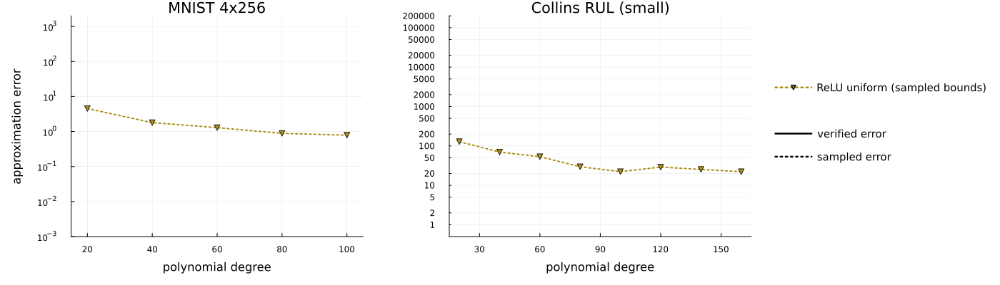

In [159]:
pl = make_evaluation_plot(1)

In [160]:
savefig(pl, "../fig/retreat/evaluation1.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/evaluation1.pdf"

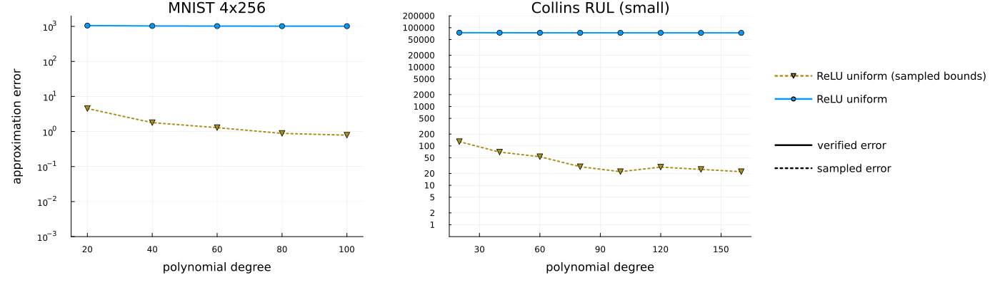

In [161]:
pl = make_evaluation_plot(2)

In [162]:
savefig(pl, "../fig/retreat/evaluation2.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/evaluation2.pdf"

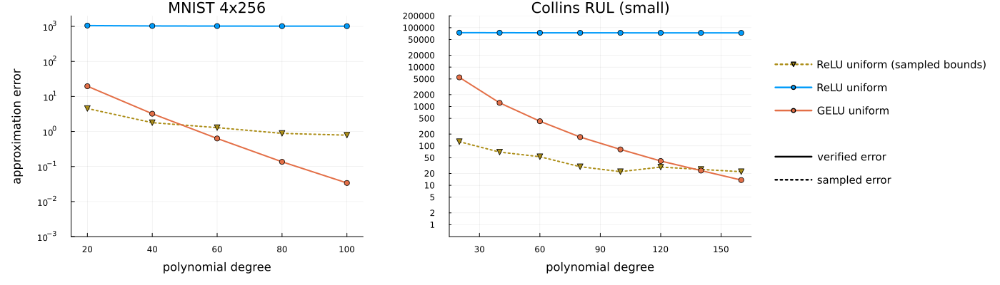

In [163]:
pl = make_evaluation_plot(3)

In [164]:
savefig(pl, "../fig/retreat/evaluation3.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/evaluation3.pdf"

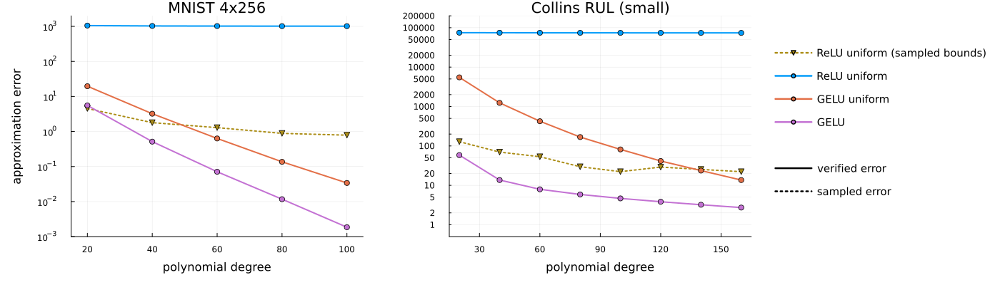

In [165]:
pl = make_evaluation_plot(4)

In [166]:
savefig(pl, "../fig/retreat/evaluation4.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/evaluation4.pdf"

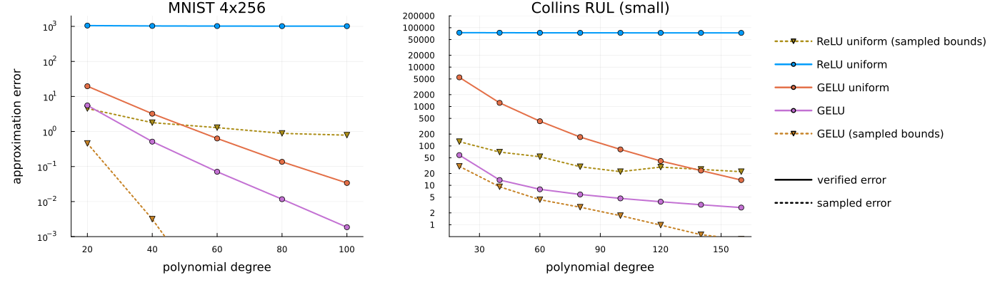

In [253]:
pl = make_evaluation_plot(5)

In [254]:
savefig(pl, "../fig/retreat/evaluation5.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/evaluation5.pdf"

# Smooth Activation Functions

In [218]:
VeryDiff.ALMOST_ZERO_LEADING_COEFF_WARNING[] = false

elu = x -> ifelse(x > 0, x, exp(x) - 1)
σ = x -> 1/(1 + exp(-x))
silu = x -> x * σ(x)



l, u = -10., 10.
degrees = 5:1:120

errors_gelu = []
errors_gelu_cheby = []
errors_relu = []
errors_relu_cheby = []
errors_elu_cheby  = []
errors_σ_cheby  = []
errors_silu_cheby  = []
for d in degrees
    # ReLU
    p_cheby = VeryDiff.chebyshev_coefficients(x -> max(0., x), l, u, d)
    xs_err, ys_err = VeryDiff.relu_error_cheby(p_cheby, l, u)
    ϵ = maximum(abs.(ys_err))
    #f = VeryDiff.make_eval_chebyshev(p_cheby, l, u)
    #ϵ, _ = error_sampling(f, x -> max(0., x), l, u) 
    push!(errors_relu_cheby, ϵ)

    p_relu, ϵ = VeryDiff.approx_relu_poly(l, u, d; max_iter=20) 
    #f = VeryDiff.make_eval_chebyshev(p_relu, l, u)
    #ϵ, _ = error_sampling(f, x -> max(0., x), l, u) 
    push!(errors_relu, ϵ)

    # ELU
    p_cheby = VeryDiff.chebyshev_coefficients(elu, l, u, d)
    # only sampled error for ELU!
    f = VeryDiff.make_eval_chebyshev(p_cheby, l, u)
    ϵ, _ = error_sampling(f, elu, l, u)    
    push!(errors_elu_cheby, ϵ)

    # sigmoid
    p_cheby = VeryDiff.chebyshev_coefficients(σ, l, u, d)
    # only sampled error for σ!
    f = VeryDiff.make_eval_chebyshev(p_cheby, l, u)
    ϵ, _ = error_sampling(f, σ, l, u)    
    push!(errors_σ_cheby, ϵ)

    # SiLU
    p_cheby = VeryDiff.chebyshev_coefficients(silu, l, u, d)
    # only sampled error for SiLU!
    f = VeryDiff.make_eval_chebyshev(p_cheby, l, u)
    ϵ, _ = error_sampling(f, silu, l, u)    
    push!(errors_silu_cheby, ϵ)
    
    # GeLU
    p_cheby = VeryDiff.chebyshev_coefficients(gelu, l, u, d)
    xs_err, ys_err = VeryDiff.piecewise_poly_error(gpp, p_cheby, l, u);
    ϵ = maximum(abs.(ys_err))
    #f = VeryDiff.make_eval_chebyshev(p_cheby, l, u)
    #ϵ, _ = error_sampling(f, gelu, l, u) 
    push!(errors_gelu_cheby, ϵ)

    p_approx_pw, ϵ = VeryDiff.remez(f_gpp, (p, l, u) -> VeryDiff.piecewise_poly_error(gpp, p, l, u), VeryDiff.poly_norm, l, u, d, verbosity=0, max_iter=20, selection=:dp)
    #f = VeryDiff.make_eval_chebyshev(p_approx_pw, l, u)
    #ϵ, _ = error_sampling(f, gelu, l, u)  
    push!(errors_gelu, ϵ)
end

In [225]:
function make_actfun_plot(step)
    lw = 3
    pl = plot(degrees, errors_relu_cheby, yscale=:log10, label="ReLU (Chebyshev)", xlabel="degree", ylabel="approximation error", legend=:bottomleft, color=1, alpha=0.5, linewidth=lw)
    step > 1 && plot!(degrees, errors_relu, label="ReLU (Remez)", color=1, linewidth=lw)
    step > 2 && plot!(degrees, errors_elu_cheby, label="ELU (Chebyshev)", color=2, alpha=0.5, linewidth=lw)
    step > 3 && plot!(degrees, errors_silu_cheby, label="SiLU (Chebyshev)", color=4, alpha=0.5, linewidth=lw)
    step > 4 && plot!(degrees, errors_gelu_cheby, label="GeLU (Chebyshev)", color=5, alpha=0.5, linewidth=lw)
    step > 5 && plot!(degrees, errors_gelu, label="GeLU (Remez)", color=5, linewidth=lw)

    return pl
end

make_actfun_plot (generic function with 1 method)

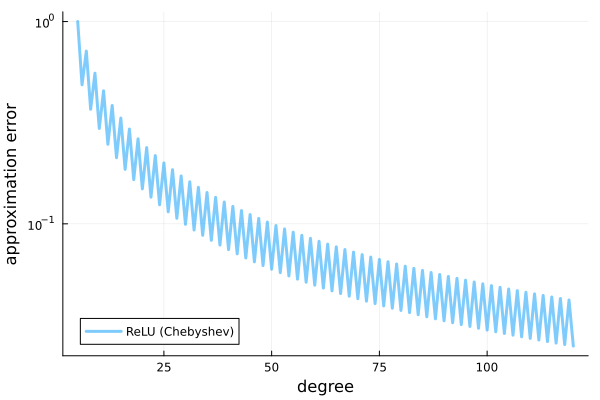

In [238]:
pl = make_actfun_plot(1)

In [239]:
savefig(pl, "../fig/retreat/actfuns1.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns1.pdf"

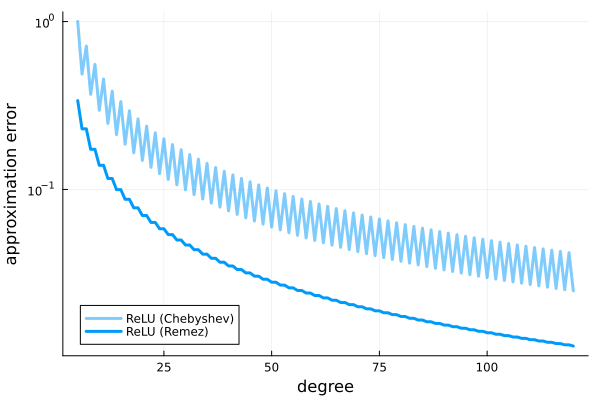

In [241]:
pl = make_actfun_plot(2)

In [242]:
savefig(pl, "../fig/retreat/actfuns2.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns2.pdf"

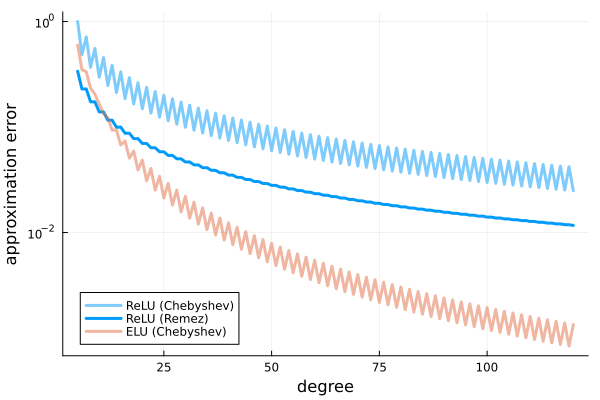

In [243]:
pl = make_actfun_plot(3)

In [244]:
savefig(pl, "../fig/retreat/actfuns3.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns3.pdf"

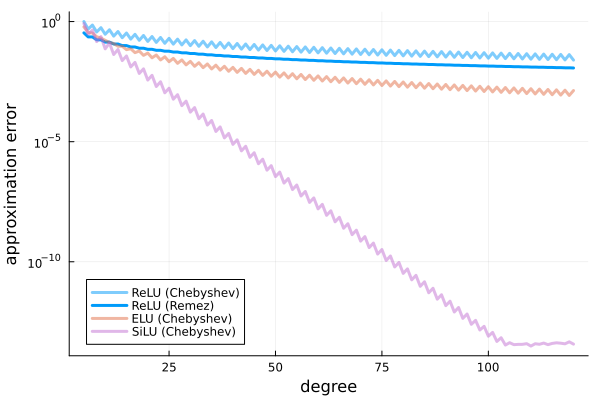

In [245]:
pl = make_actfun_plot(4)

In [246]:
savefig(pl, "../fig/retreat/actfuns4.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns4.pdf"

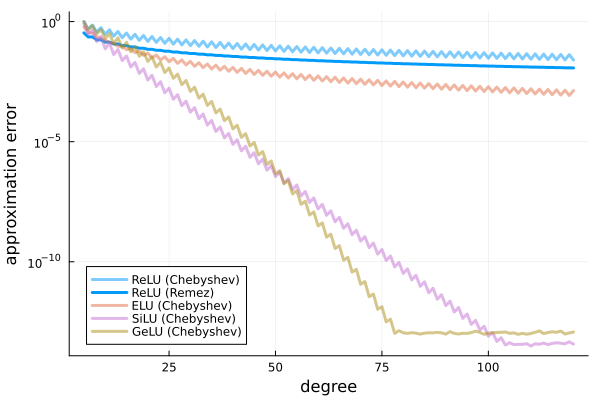

In [247]:
pl = make_actfun_plot(5)

In [248]:
savefig(pl, "../fig/retreat/actfuns5.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns5.pdf"

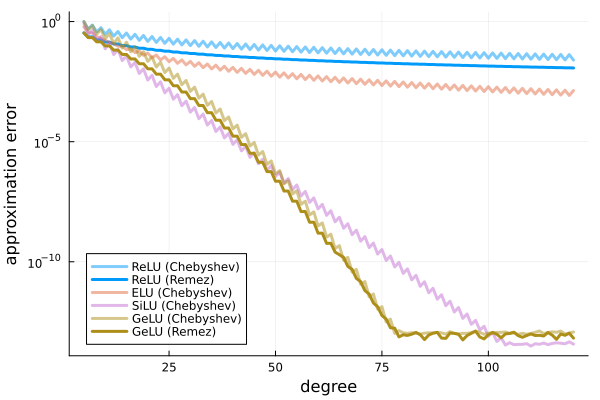

In [249]:
pl = make_actfun_plot(6)

In [250]:
savefig(pl, "../fig/retreat/actfuns6.pdf")

"/home/philipp/VerifyNN/VeryDiffPolyExperiments/analysis/fig/retreat/actfuns6.pdf"

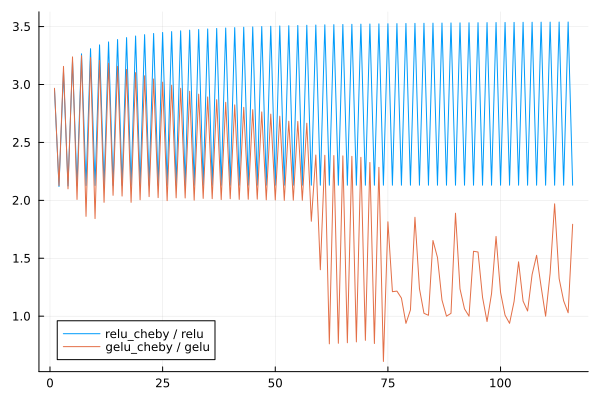

In [237]:
plot(errors_relu_cheby ./ errors_relu, label="relu_cheby / relu")
plot!(errors_gelu_cheby ./ errors_gelu, label="gelu_cheby / gelu")